# Crypto and the macro environment

This notebook looks at how Bitcoin and Ethereum move together with US markets and macroeconomic data
between 2020 and September 2026. Crypto prices come from Coinbase and the macro series from FRED
(the St. Louis Fed). It asks four questions: how closely crypto follows stocks, how it reacts to
interest-rate changes in different Fed regimes, how it behaves around CPI inflation releases, and whether it acts
as a hedge against inflation or a weaker dollar. Everything shown below is computed from the saved
files in `data/raw/`; run `python -m cryptomacro.acquire` once first to download them.

In [1]:
import sys
sys.path.insert(0, ".")  # the notebook is opened from the project folder, which holds cryptomacro/

import matplotlib.pyplot as plt
import pandas as pd

from cryptomacro import analysis, config, plots
from cryptomacro.clean import DataMissingError, load_dropped_cpi_dates
from cryptomacro.dashboard import build_dashboard, load_all

%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


In [2]:
try:
    data = load_all()
except DataMissingError as error:
    print(error)
    data = None

if data is not None:
    # Compare this count (about 80) with the BLS CPI schedule after the first real download.
    print(f"CPI release dates used: {len(data['cpi_dates'])}")
    dropped = load_dropped_cpi_dates()
    if len(dropped):
        print("Dropped (a later date in the same month was kept):",
              ", ".join(f"{day:%Y-%m-%d}" for day in dropped))

CPI release dates used: 80
Dropped (a later date in the same month was kept): 2020-02-11, 2021-02-08, 2022-02-08, 2023-02-10, 2024-02-09


## The data at a glance

Count, mean, spread and range of each daily change in the panel (returns for prices, differences for rates).

In [3]:
if data is not None:
    display(analysis.describe_changes(data["panel"]))

,BTC_ret,ETH_ret,SP500_ret,NASDAQCOM_ret,DGS10_chg,DFF_chg,T10YIE_chg,DTWEXBGS_ret
count,1694.000000,1694.000000,1694.000000,1694.000000,1672.000000,1694.000000,1672.000000,1662.000000
mean,0.001468,0.001802,0.000504,0.000639,0.002135,0.001375,0.000395,0.000027
std,0.038812,0.051928,0.012769,0.015561,0.059278,0.052575,0.034129,0.003273
min,-0.491226,-0.567794,-0.127652,-0.131492,-0.300000,-0.850000,-0.320000,-0.018918
25%,-0.016161,-0.022654,-0.004758,-0.006554,-0.030000,0.000000,-0.020000,-0.001751
50%,0.000707,0.001042,0.000878,0.001355,0.000000,0.000000,0.000000,-0.000114
75%,0.019641,0.026546,0.006709,0.009001,0.040000,0.000000,0.020000,0.001840
max,0.192586,0.345765,0.090895,0.114784,0.290000,0.750000,0.250000,0.018924


## Explore: pick a coin, a series and a window

Choose a coin, one of the six macro series and the rolling-window length. The first chart shows the rolling
correlation between the coin's daily return and the series' daily change, with its highest point marked. The
second compares volatility and volume on CPI release days with other weekdays. The table summarizes the choice;
the coin's annualized volatility uses its daily candles for every calendar day (x sqrt 365), and the S&P 500's uses
trading days (x sqrt 252).

In [4]:
if data is not None:
    display(build_dashboard(data))

## Question 1: Does crypto move with the stock market?

For each day we take the coin's log return and the index's log return, then compute their correlation over a
rolling window (90 days by default). A value near 1 means they tend to move the same way, near 0 means no
link, and below 0 means opposite directions. The table also compares daily changes with weekly changes, because
daily data mixes weekends (crypto trades, stocks do not) into Monday's move.

In [5]:
PAIRS = [(coin, series) for coin in config.PRODUCTS for series in ["SP500", "NASDAQCOM"]]
if data is not None:
    tables = {f"{coin} vs {series}": analysis.weekly_comparison(data["panel"], coin, series) for coin, series in PAIRS}
    display(pd.concat(tables, names=["pair", "frequency"]))

correlation     n
pair             frequency                   
BTC vs SP500     daily         0.394087  1694
                 weekly        0.281259   352
BTC vs NASDAQCOM daily         0.414127  1694
                 weekly        0.310492   352
ETH vs SP500     daily         0.405050  1694
                 weekly        0.371261   352
ETH vs NASDAQCOM daily         0.422696  1694
                 weekly        0.380790   352

BTC vs SP500: peak 0.62 on 2026-02-11


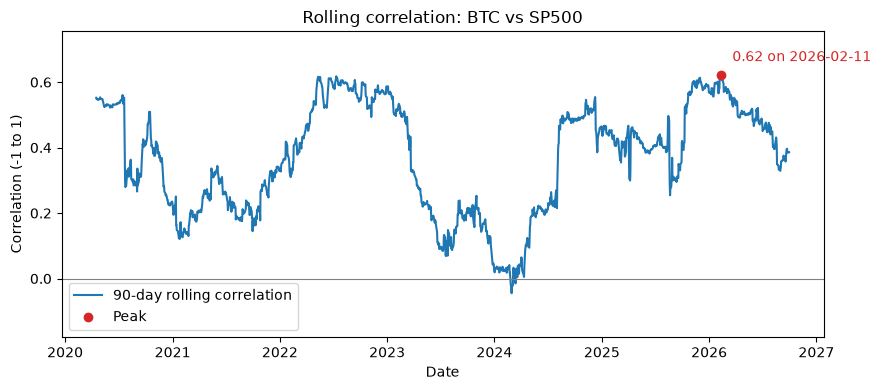

BTC vs NASDAQCOM: peak 0.67 on 2022-05-12


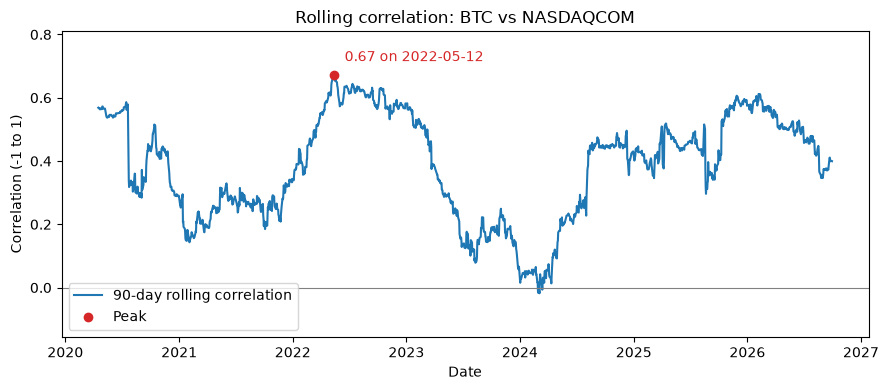

ETH vs SP500: peak 0.69 on 2022-05-18


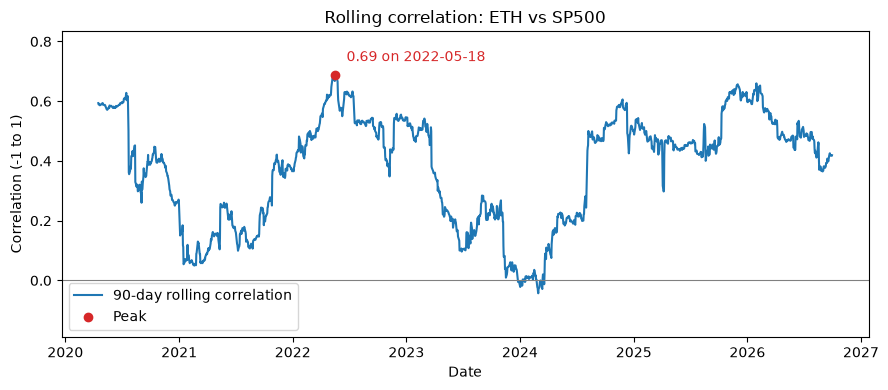

ETH vs NASDAQCOM: peak 0.73 on 2022-05-11


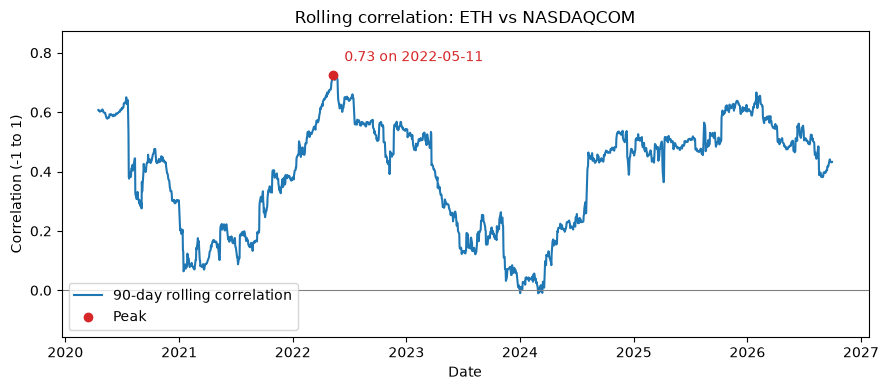

In [6]:
if data is not None:
    for coin, series in PAIRS:
        corr = analysis.rolling_correlation(data["panel"], coin, series, config.DEFAULT_WINDOW)
        peak_date, peak_value = analysis.correlation_peak(corr)
        if peak_date is None:
            print(f"{coin} vs {series}: no peak — not enough data")
        else:
            print(f"{coin} vs {series}: peak {peak_value:.2f} on {peak_date:%Y-%m-%d}")
        plots.plot_rolling_correlation(corr, (peak_date, peak_value), config.DEFAULT_WINDOW)
        plt.show()

## Question 2: Does crypto react to interest rates differently when the Fed is cutting, holding or raising?

Each day is labelled by the change in the fed funds rate over the previous 90 days: a fall of at least 0.125
percentage points is "cutting", a rise of at least 0.125 is "raising", anything in between is "holding".
Within each regime we fit a straight line of the coin's daily return on the daily change in the 10-year
Treasury yield. The slope (beta) says how much the return moves per one percentage point change in the yield;
the n column shows how many days each estimate rests on, so read small n with caution.

In [7]:
if data is not None:
    betas = analysis.rate_beta_by_regime(data["panel"], "BTC")
    display(betas)

,alpha,beta,corr,n
cutting,-0.000039,0.071894,0.088424,324
holding,0.002426,0.037244,0.050723,940
raising,0.000558,-0.077054,-0.164084,408
all,0.001385,-0.004660,-0.007124,1672


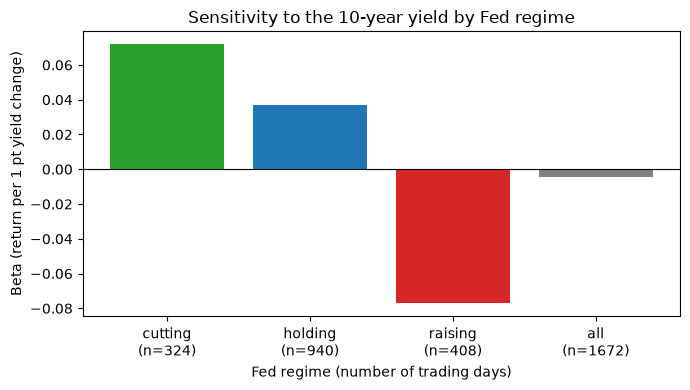

In [8]:
if data is not None:
    plots.plot_regime_betas(betas)
    plt.show()

## Question 3: What happens to crypto around CPI inflation releases?

CPI is published at 8:30 AM Eastern. We use hourly candles and call the candle containing 8:30 "hour 0". The
table compares realized volatility (the spread of hourly returns) and trading volume on CPI days with other
weekdays. The profile plot shows the average absolute hourly return from 6 hours before to 12 hours after the
release; the grey band is where ordinary days land 95% of the time (found by resampling ordinary days 2,000
times), so CPI hours above the band are unusually large moves. The reaction length is the number of hours until
the CPI line is back inside the band.

,realized_vol_mean,realized_vol_std,volume_mean,n_days
cpi_day,,,,
False,0.005853,0.003819,16891.641012,1680
True,0.006627,0.003968,19153.592338,80


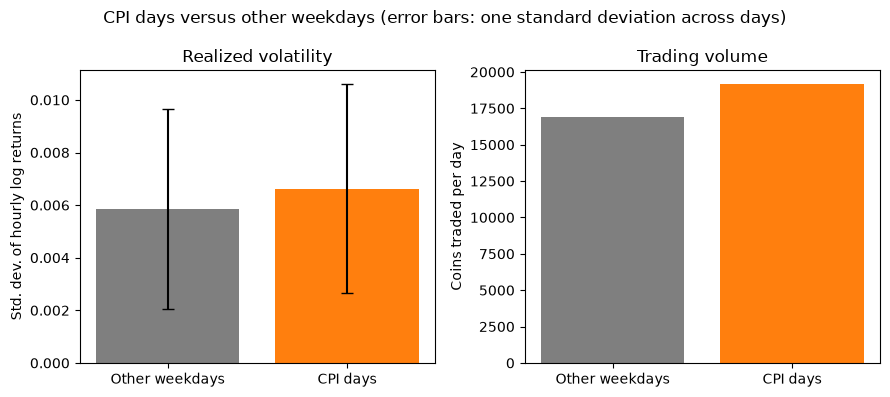

In [9]:
if data is not None:
    comparison = analysis.daily_event_comparison(data["hourly"]["BTC"], data["cpi_dates"])
    display(comparison)
    plots.plot_event_comparison(comparison)
    plt.show()

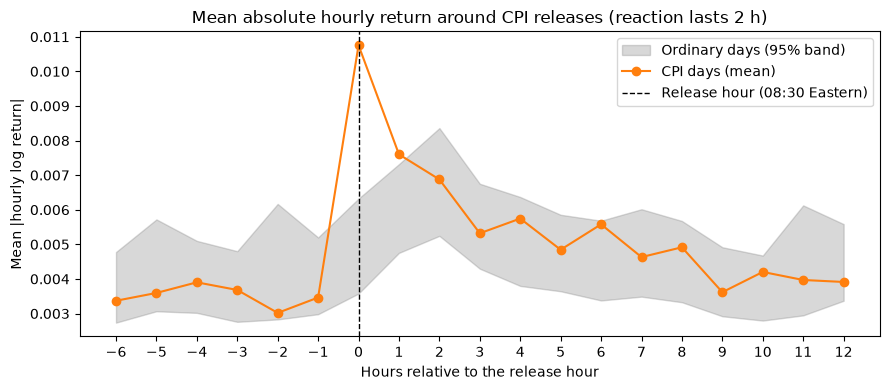

The CPI reaction lasts 2 hour(s).


In [10]:
if data is not None:
    profile = analysis.event_window_profile(data["hourly"]["BTC"], data["cpi_dates"])
    reaction = analysis.reaction_hours(profile)
    plots.plot_event_profile(profile, reaction)
    plt.show()
    if reaction is None:
        print("Hour 0 is not above the ordinary-day band: no CPI reaction detected.")
    elif reaction > config.EVENT_HOURS_AFTER:
        print(f"The CPI reaction lasts beyond +{config.EVENT_HOURS_AFTER} h (still above the band at the end of the window).")
    else:
        print(f"The CPI reaction lasts {reaction} hour(s).")

## Question 4: Is crypto a hedge against inflation or a weaker dollar?

We correlate the coin's daily return with the daily change in 10-year breakeven inflation (the market's
inflation expectation) and with the daily return of the trade-weighted dollar index. A hedge would show a
positive link to inflation expectations and a negative link to the dollar. The tables give the full-sample
correlations and one row per calendar year; the line chart shows how the links drift over time, and the last
chart puts the three levels on one scale (z-scores) to compare their long-run shapes.

In [11]:
if data is not None:
    display(analysis.hedge_correlation_matrix(data["panel"], "BTC"))
    display(analysis.hedge_correlation_by_year(data["panel"], "BTC"))

,BTC,Breakeven inflation,Dollar index
BTC,1.000000,0.117059,-0.214553
Breakeven inflation,0.117059,1.000000,-0.054333
Dollar index,-0.214553,-0.054333,1.000000


,corr_inflation,corr_dollar,n
year,,,
2020,0.193800,-0.329312,244
2021,0.101017,-0.163232,245
2022,0.106093,-0.310690,246
2023,-0.046955,-0.101373,246
2024,0.155077,-0.079297,248
2025,0.144979,-0.182716,246
2026,0.090741,-0.217817,187


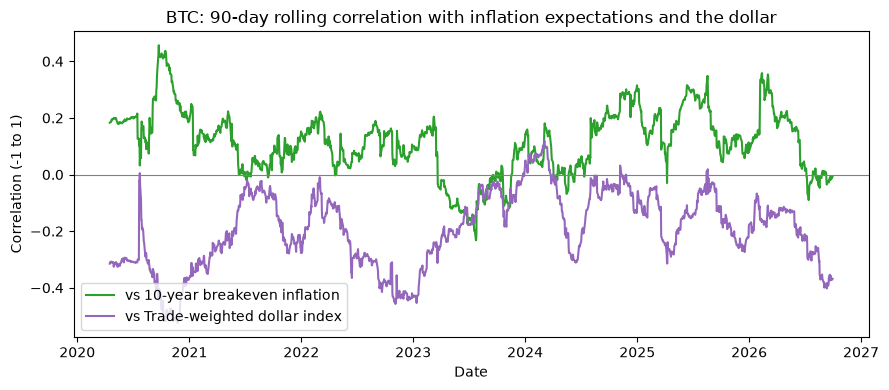

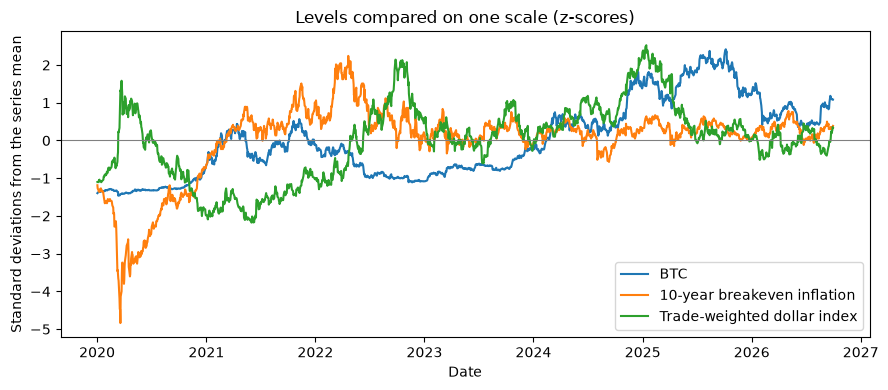

In [12]:
if data is not None:
    plots.plot_hedge(data["panel"], "BTC", config.DEFAULT_WINDOW)
    plt.show()
    plots.plot_zscores(data["panel"], "BTC")
    plt.show()